# 1. Import Smoke Images and Labels

Images and labels are saved in separate folders. The label filenames are used to filter the unlabeled images from the labeled images. Both files are saved and uploaded from google drive.


In [3]:
from pathlib import Path

# Root directory of the local wildfire project
PROJECT_DIR = Path.cwd()

# Existing project folders
DATASETS_DIR = PROJECT_DIR / "datasets"
MODELS_DIR = PROJECT_DIR / "models"
EXPERIMENTS_DIR = PROJECT_DIR / "experiments"
EVALUATION_DIR = PROJECT_DIR / "evaluations"

# Verify that the folders are accessible
print("Project directory:", PROJECT_DIR)
print("Datasets found:", DATASETS_DIR.exists())
print("Models found:", MODELS_DIR.exists())
print("Experiments found:", EXPERIMENTS_DIR.exists())
print("Evaluations found:", EVALUATION_DIR.exists())

# List dataset configuration files
print("DATASET CONFIGURATIONS")
for path in DATASETS_DIR.rglob("data.yaml"):
    print(path.relative_to(PROJECT_DIR))

# List saved YOLO model checkpoints
print("\nMODEL CHECKPOINTS")
for path in PROJECT_DIR.rglob("best.pt"):
    if ".venv" not in path.parts:
        print(path.relative_to(PROJECT_DIR))

# Show the contents of each dataset folder
for folder in sorted(DATASETS_DIR.iterdir()):
    if folder.is_dir():
        print(f"\n{folder.name}/")

        for item in sorted(folder.iterdir()):
            print(f"  {item.name}")

Project directory: d:\Projects\Wildfire_Smoke_Project
Datasets found: True
Models found: True
Experiments found: True
Evaluations found: True
DATASET CONFIGURATIONS
datasets\experiment_2\data.yaml

MODEL CHECKPOINTS
experiments\experiment_1_resolution960\weights\best.pt
experiments\experiment_2_negative_images\weights\best.pt
experiments\experiment_3_yolo11s\weights\best.pt

experiment_2/
  data.yaml
  images
  labels


In [3]:
# @title
import pandas as pd
from pathlib import Path
from google.colab import drive
drive.mount('/content/drive')

images_dir = Path('/content/drive/MyDrive/smoke_images')
labels_dir = Path('/content/drive/MyDrive/smoke_labels')

# Sort all images
images = sorted(images_dir.glob('*.jpg'))

# Find images with labels and save them as list of tuples
labeled_images = []
for image in images:
  label = labels_dir / (image.stem + '.txt')
  if label.exists():
    labeled_images.append((image, label))

print("Total: ", len(labeled_images))
print("EX: ", labeled_images[0])


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Total:  824
EX:  (PosixPath('/content/drive/MyDrive/smoke_images/1610044421_+00120.jpg'), PosixPath('/content/drive/MyDrive/smoke_labels/1610044421_+00120.txt'))


# 2. Group Labeled Frames by Video ID

Image filenames hold a timestamp that provides the date of the video and an offset that gives the time in the video that the frame was taken from. These timestamps are separated by either "_+" or "_-". Depending on the separation symbol, the video ID can be determined by either adding or subtracting the timestamp and offset. <br>

Images are then placed in a dictionary with lists of frames in order to group frames from the same video together. This step allows splitting the dataset by videos instead of individual frames which guarantees that frames from the same video are placed in the same split.

In [4]:
# @title
# Get video ids from the file names
# First number in filename is timestamp & second number is offset
def get_video_id(image):
    filename = image.stem

    # For "+" subtract timestamp by offset
    if '_+' in filename:
      timestamp, offset = filename.split('_+')
      return int(timestamp) - int(offset)

    # For "-" add timestamp and offset
    elif '_-' in filename:
      timestamp, offset = filename.split('_-')
      return int(timestamp) + int(offset)

    # Return errors for files without this naming convention
    else:
      return ValueError(f"Unknown filename format: {filename}")

In [5]:
# @title
# Create a dictionary that stores video frames based on their video id
video_groups = {}

for image, label in labeled_images:
    # Get the image's video id
    video_id = get_video_id(image)

    # If the video id is not in the dict, add it
    if video_id not in video_groups:
        video_groups[video_id] = []

    # Add image and label to the video grouping
    video_groups[video_id].append((image, label))

print("Total labeled images:", len(labeled_images))
print("Total video groups:", len(video_groups))

for video_id, pairs in sorted(video_groups.items()):
    print(f"Video {video_id}: {len(pairs)} images")

Total labeled images: 824
Total video groups: 40
Video 1610044301: 30 images
Video 1610305086: 20 images
Video 1610572103: 16 images
Video 1610572207: 22 images
Video 1612465753: 6 images
Video 1612892967: 13 images
Video 1628643180: 22 images
Video 1644860530: 23 images
Video 1646241702: 3 images
Video 1706635071: 15 images
Video 1706729406: 19 images
Video 1706797129: 29 images
Video 1715567915: 27 images
Video 1715715576: 26 images
Video 1715792914: 30 images
Video 1717877171: 8 images
Video 1718565180: 24 images
Video 1719093898: 31 images
Video 1719349541: 20 images
Video 1719855050: 26 images
Video 1719855058: 29 images
Video 1719855181: 25 images
Video 1719855218: 12 images
Video 1719873299: 30 images
Video 1720305905: 21 images
Video 1721348657: 28 images
Video 1721428613: 28 images
Video 1722196441: 44 images
Video 1722631648: 18 images
Video 1731098333: 8 images
Video 1731098589: 5 images
Video 1737564864: 11 images
Video 1737667438: 5 images
Video 1737670364: 24 images
Video

# 3. Split data into Training and Validation Sets
Creates training and validation sets using group random shuffle splitting to separate the data by videos. The split is 80:20 for 40 videos total. Therefore there are 32 videos in training and 8 videos in validation. <br>

Checking the splits is required to make sure the amount of individual frames is close to an 80:20 split. Given the reproducible conditions, the dataset should have about 77% of images in training and the other 23% should be in validation. Finally, ensure that no video shows up in both the training and validation set.

In [6]:
# @title
from sklearn.model_selection import GroupShuffleSplit

# Get the video id for each labeled image
groups = [get_video_id(image) for image, label in labeled_images]

# Create splitter that will put 20% of the videos in validation set
splitter = GroupShuffleSplit(test_size=0.2, n_splits=1, random_state=42)

# Split the data into training and validation
train_indices, val_indices = next(splitter.split(labeled_images, groups=groups))

train_data = [labeled_images[i] for i in train_indices]
val_data = [labeled_images[i] for i in val_indices]

print("Training data percentage:", len(train_data)/len(labeled_images))
print("Validation data percentage:", len(val_data)/len(labeled_images))

Training data percentage: 0.7682038834951457
Validation data percentage: 0.23179611650485438


In [7]:
# @title
# Check that the video split is 80:20 and no video appears in both sets
train_videos = {groups[i] for i in train_indices}
val_videos = {groups[i] for i in val_indices}

print("Training videos:", len(train_videos))
print("Validation videos:", len(val_videos))
print("Overlapping videos:", train_videos & val_videos)

Training videos: 32
Validation videos: 8
Overlapping videos: set()


#4. Save splits into YOLO compatable files
YOLO requires a specific file hierarchy:

**smoke dataset** <br>
|---*images* <br>
|--------training <br>
|--------validation <br>
|---*labels* <br>
|--------training <br>
|--------validation <br>

The code below creates this hierarchy in google drive and copies the images and labels into their correct files. The .yaml file is also created which sets the configuration for the YOLO model.

In [ ]:
# @title
import shutil

# Directory path for new YOLO dataset
dataset_dir = PROJECT_DIR / "datasets"

# Create requried folders
for split in ['train', 'val']:
  (dataset_dir / 'images' / split).mkdir(parents=True, exist_ok=True)
  (dataset_dir / 'labels' / split).mkdir(parents=True, exist_ok=True)

# Store training and validation data
splits = {
    'train': train_data,
    'val': val_data
}

# Copy from original files into dataset files
for split, data in splits.items():
  for image, label in data:
    # Copy image to dataset directory
    shutil.copy(image, dataset_dir / 'images' / split / image.name)

    # Copy label to dataset directory
    shutil.copy(label, dataset_dir / 'labels' / split / label.name)

  print(f"{split}: {len(data)} image-label pairs copied")



train: 633 image-label pairs copied
val: 191 image-label pairs copied


In [9]:
# @title
import yaml

# Create data.yaml (configuration file for YOLO)
data = {
    'path': str(dataset_dir),
    'train': 'images/train',
    'val': 'images/val',
    'nc': 1,
    'names': {0: 'smoke'}
}

with open(dataset_dir / 'data.yaml', 'w') as f:
    yaml.safe_dump(data, f, sort_keys=False)

# 5. Load a pretrained YOLO model and train it on Smoke dataset

In [11]:
# @title



# BASELINE TRAINING — ALREADY COMPLETED
#
# This cell trains the original YOLO11n baseline from pretrained weights.
# The trained model is saved as baseline_best.pt in our shared folder.
#
# DO NOT run this cell during normal evaluation.
# Instead, load the saved checkpoint using the cell below.



# UNCOMMENT NEXT LINE FOR FIRST RUN
#!pip install -q ultralytics
from ultralytics import YOLO

# Load pretrained YOLO model
model = YOLO('yolo11n.pt')

# Train on our smoke dataset
results = model.train(
    data=str(dataset_dir / 'data.yaml'),
    epochs=50,
    imgsz=640,
    batch=16,
    device=0,
    seed=42,
    deterministic=True,
    project='/content/drive/MyDrive/smoke_training',
    name='baseline'
)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Ultralytics 8.4.215 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=content/drive/MyDrive/smoke_dataset/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript

In [14]:
from ultralytics import YOLO
from pathlib import Path

# Location of the team's shared baseline checkpoint
BASELINE_PATH = Path(
    "/content/drive/MyDrive/Wildfire_Smoke_Project/models/baseline_best.pt"
)

# Verify the checkpoint exists before loading it
assert BASELINE_PATH.exists(), f"Model not found: {BASELINE_PATH}"

# Load the previously trained model without retraining
baseline_model = YOLO(str(BASELINE_PATH))

print("Shared baseline loaded successfully!")

Shared baseline loaded successfully!


# 6. Evaluate baseline YOLO

In [17]:
from pathlib import Path

# Shared folder for all model evaluation results
EVALUATION_DIR = Path(
    "/content/drive/MyDrive/Wildfire_Smoke_Project/evaluations"
)

# Evaluate our saved baseline and store the results in Google Drive
baseline_metrics = baseline_model.val(
    data=str(dataset_dir / "data.yaml"),
    split="val",
    plots=True,
    project=str(EVALUATION_DIR),
    name="baseline",
    exist_ok=True
)

# Calculate the baseline F1 score
precision = baseline_metrics.box.mp
recall = baseline_metrics.box.mr

f1 = (
    2 * precision * recall / (precision + recall)
    if precision + recall > 0
    else 0.0
)

# Display the evaluation metrics
print(f"Precision: {precision:.4f}")
print(f"Recall: {recall:.4f}")
print(f"F1: {f1:.4f}")
print(f"mAP@0.5: {baseline_metrics.box.map50:.4f}")
print(f"mAP@0.5:0.95: {baseline_metrics.box.map:.4f}")

print(f"\nEvaluation results saved to: {baseline_metrics.save_dir}")

Ultralytics 8.4.215 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11n summary (fused): 101 layers, 2,597,051 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 3682.9±820.1 MB/s, size: 547.5 KB)
val: Scanning /content/content/drive/MyDrive/smoke_dataset/labels/val.cache... 191 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 191/191 13.1Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 12/12 1.5it/s 7.8s
                   all        191        191       0.62      0.341      0.369      0.164
Speed: 2.0ms preprocess, 3.9ms inference, 0.0ms loss, 2.9ms postprocess per image
Results saved to /content/drive/MyDrive/Wildfire_Smoke_Project/evaluations/baseline
Precision: 0.6197
Recall: 0.3413
F1: 0.4402
mAP@0.5: 0.3689
mAP@0.5:0.95: 0.1639

Evaluation results saved to: /content/drive/MyDrive/Wildfire_Smoke_Project/evaluations/baseline


Investigate errors using confusion matrix

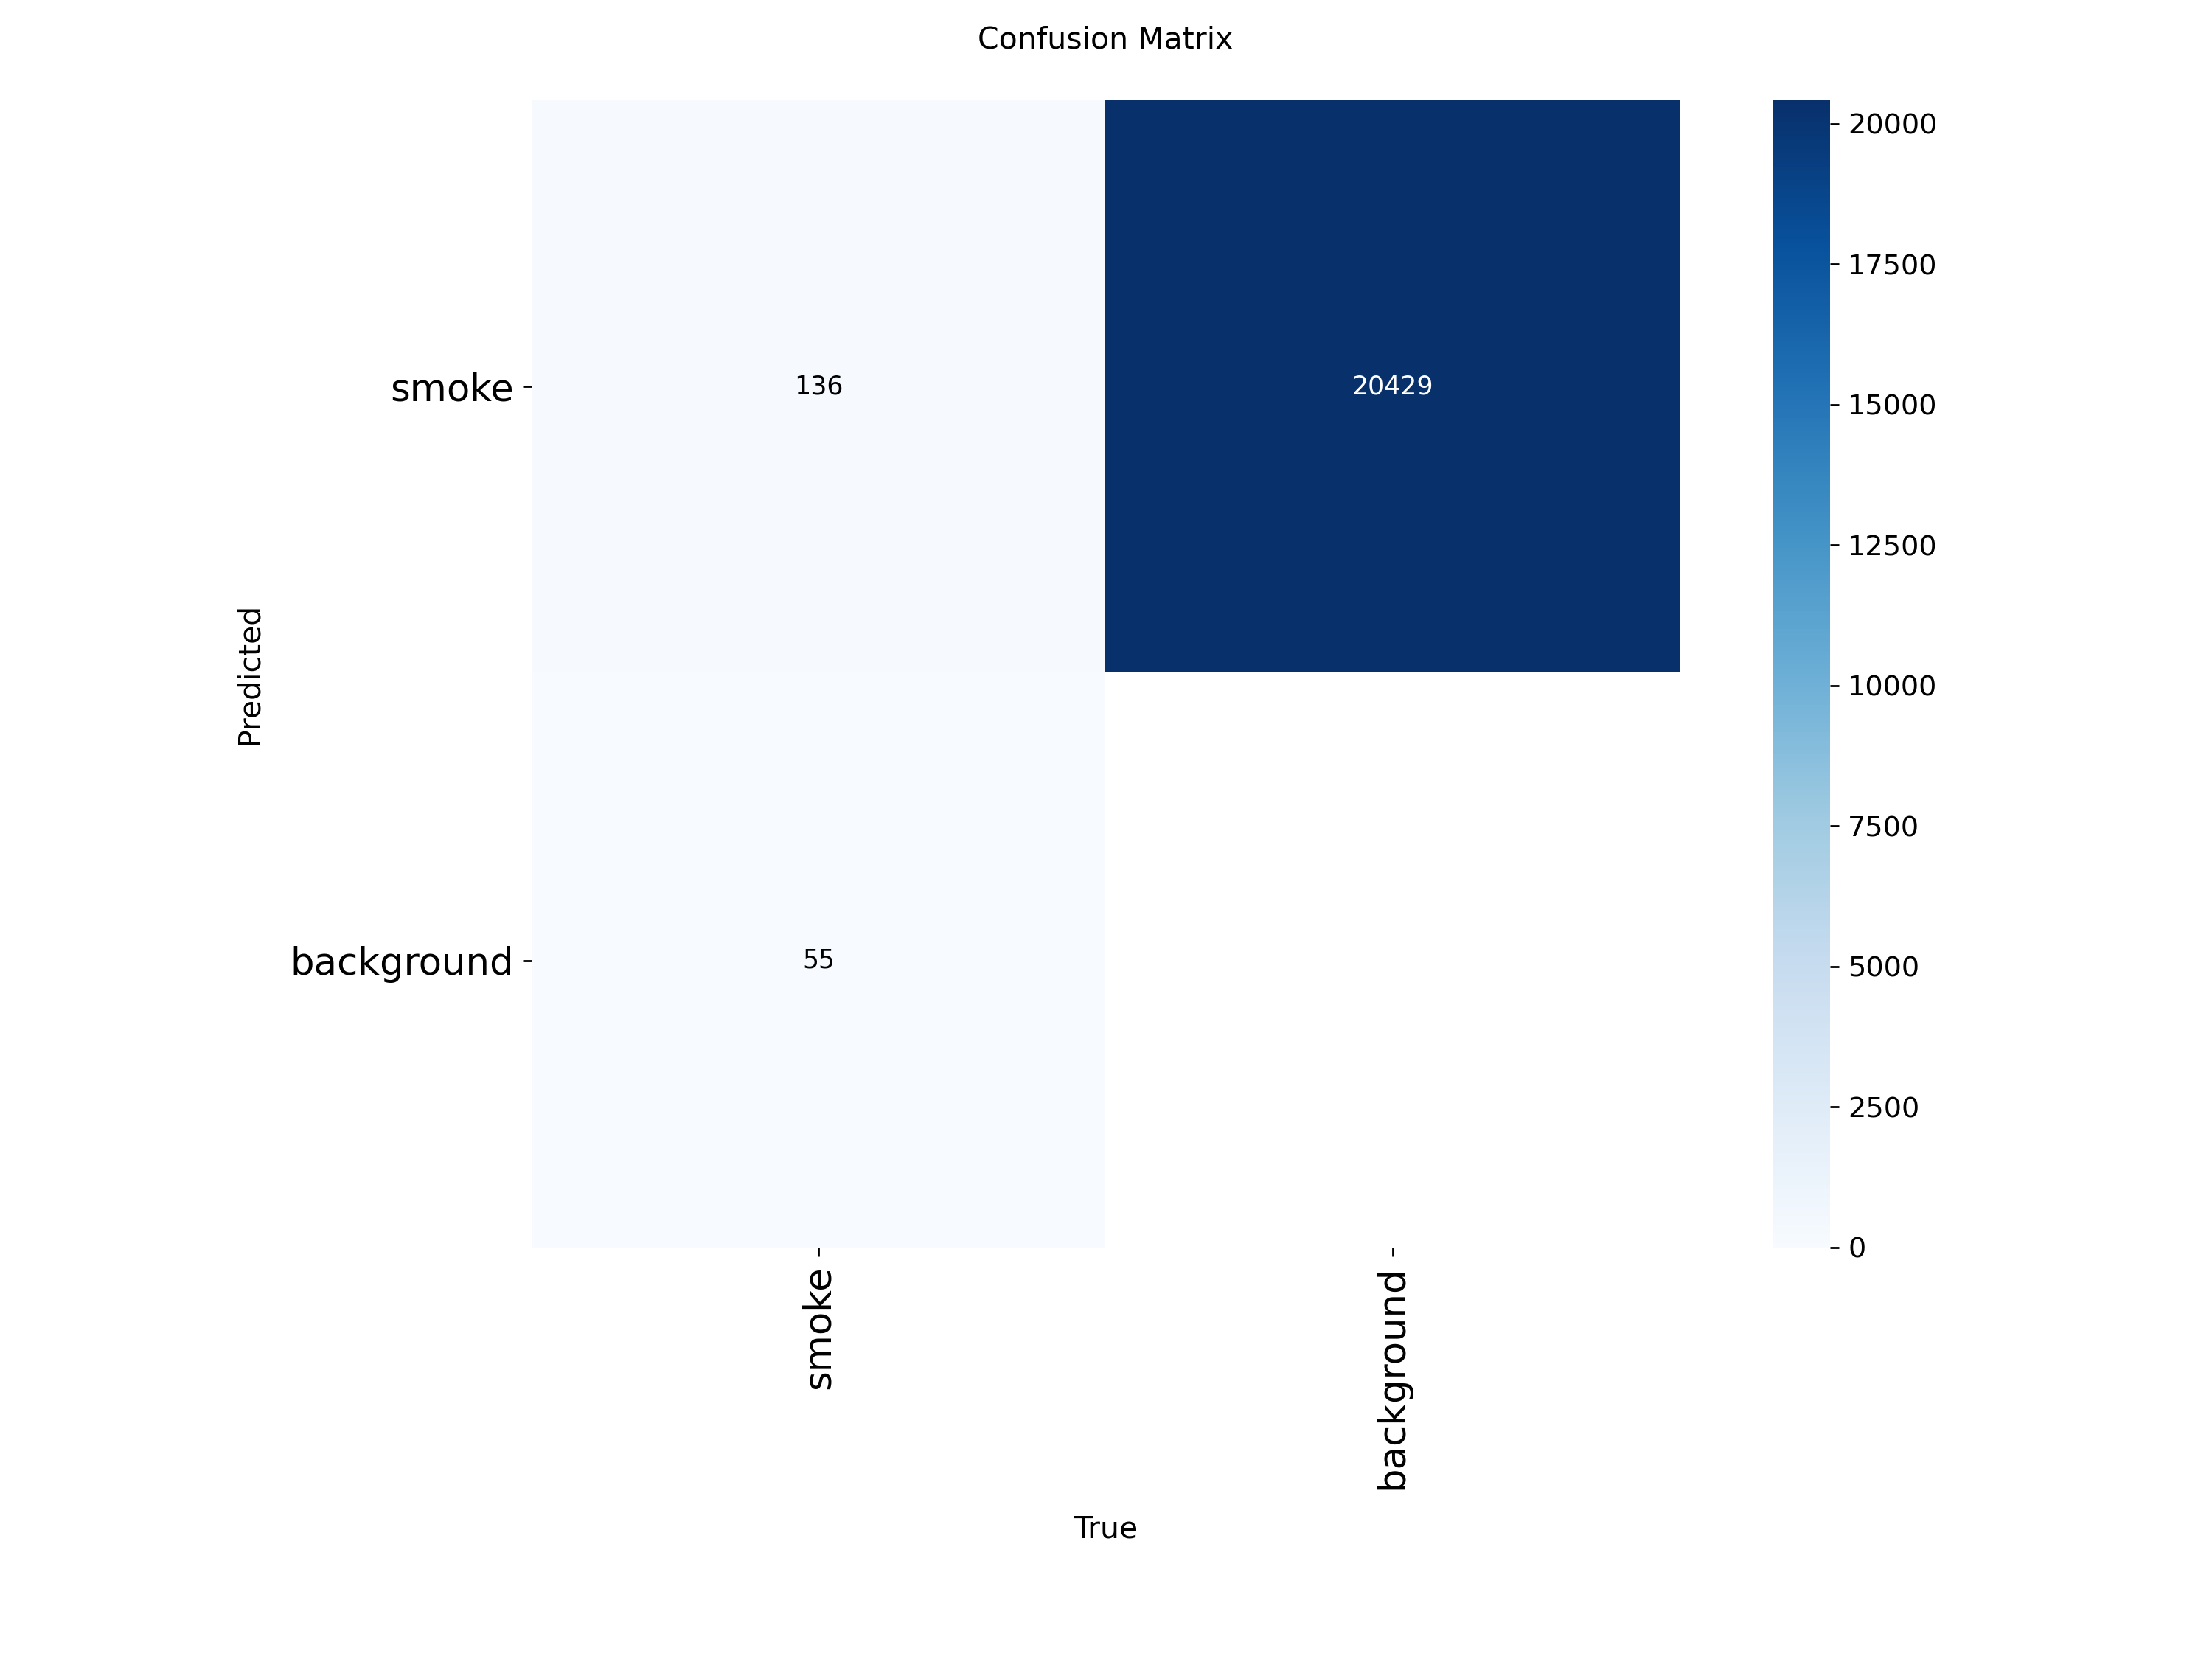

In [18]:
from IPython.display import Image, display

# Display the confusion matrix saved during baseline evaluation
confusion_matrix_path = EVALUATION_DIR / "baseline" / "confusion_matrix.png"

display(Image(filename=str(confusion_matrix_path), width=700))

Ultralytics 8.4.215 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11n summary (fused): 101 layers, 2,597,051 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 3835.4±795.1 MB/s, size: 498.8 KB)
val: Scanning /content/content/drive/MyDrive/smoke_dataset/labels/val.cache... 191 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 191/191 33.4Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 12/12 2.2it/s 5.4s
                   all        191        191       0.62      0.341      0.336      0.153
Speed: 1.7ms preprocess, 3.8ms inference, 0.0ms loss, 1.4ms postprocess per image
Results saved to /content/drive/MyDrive/Wildfire_Smoke_Project/evaluations/baseline_conf025


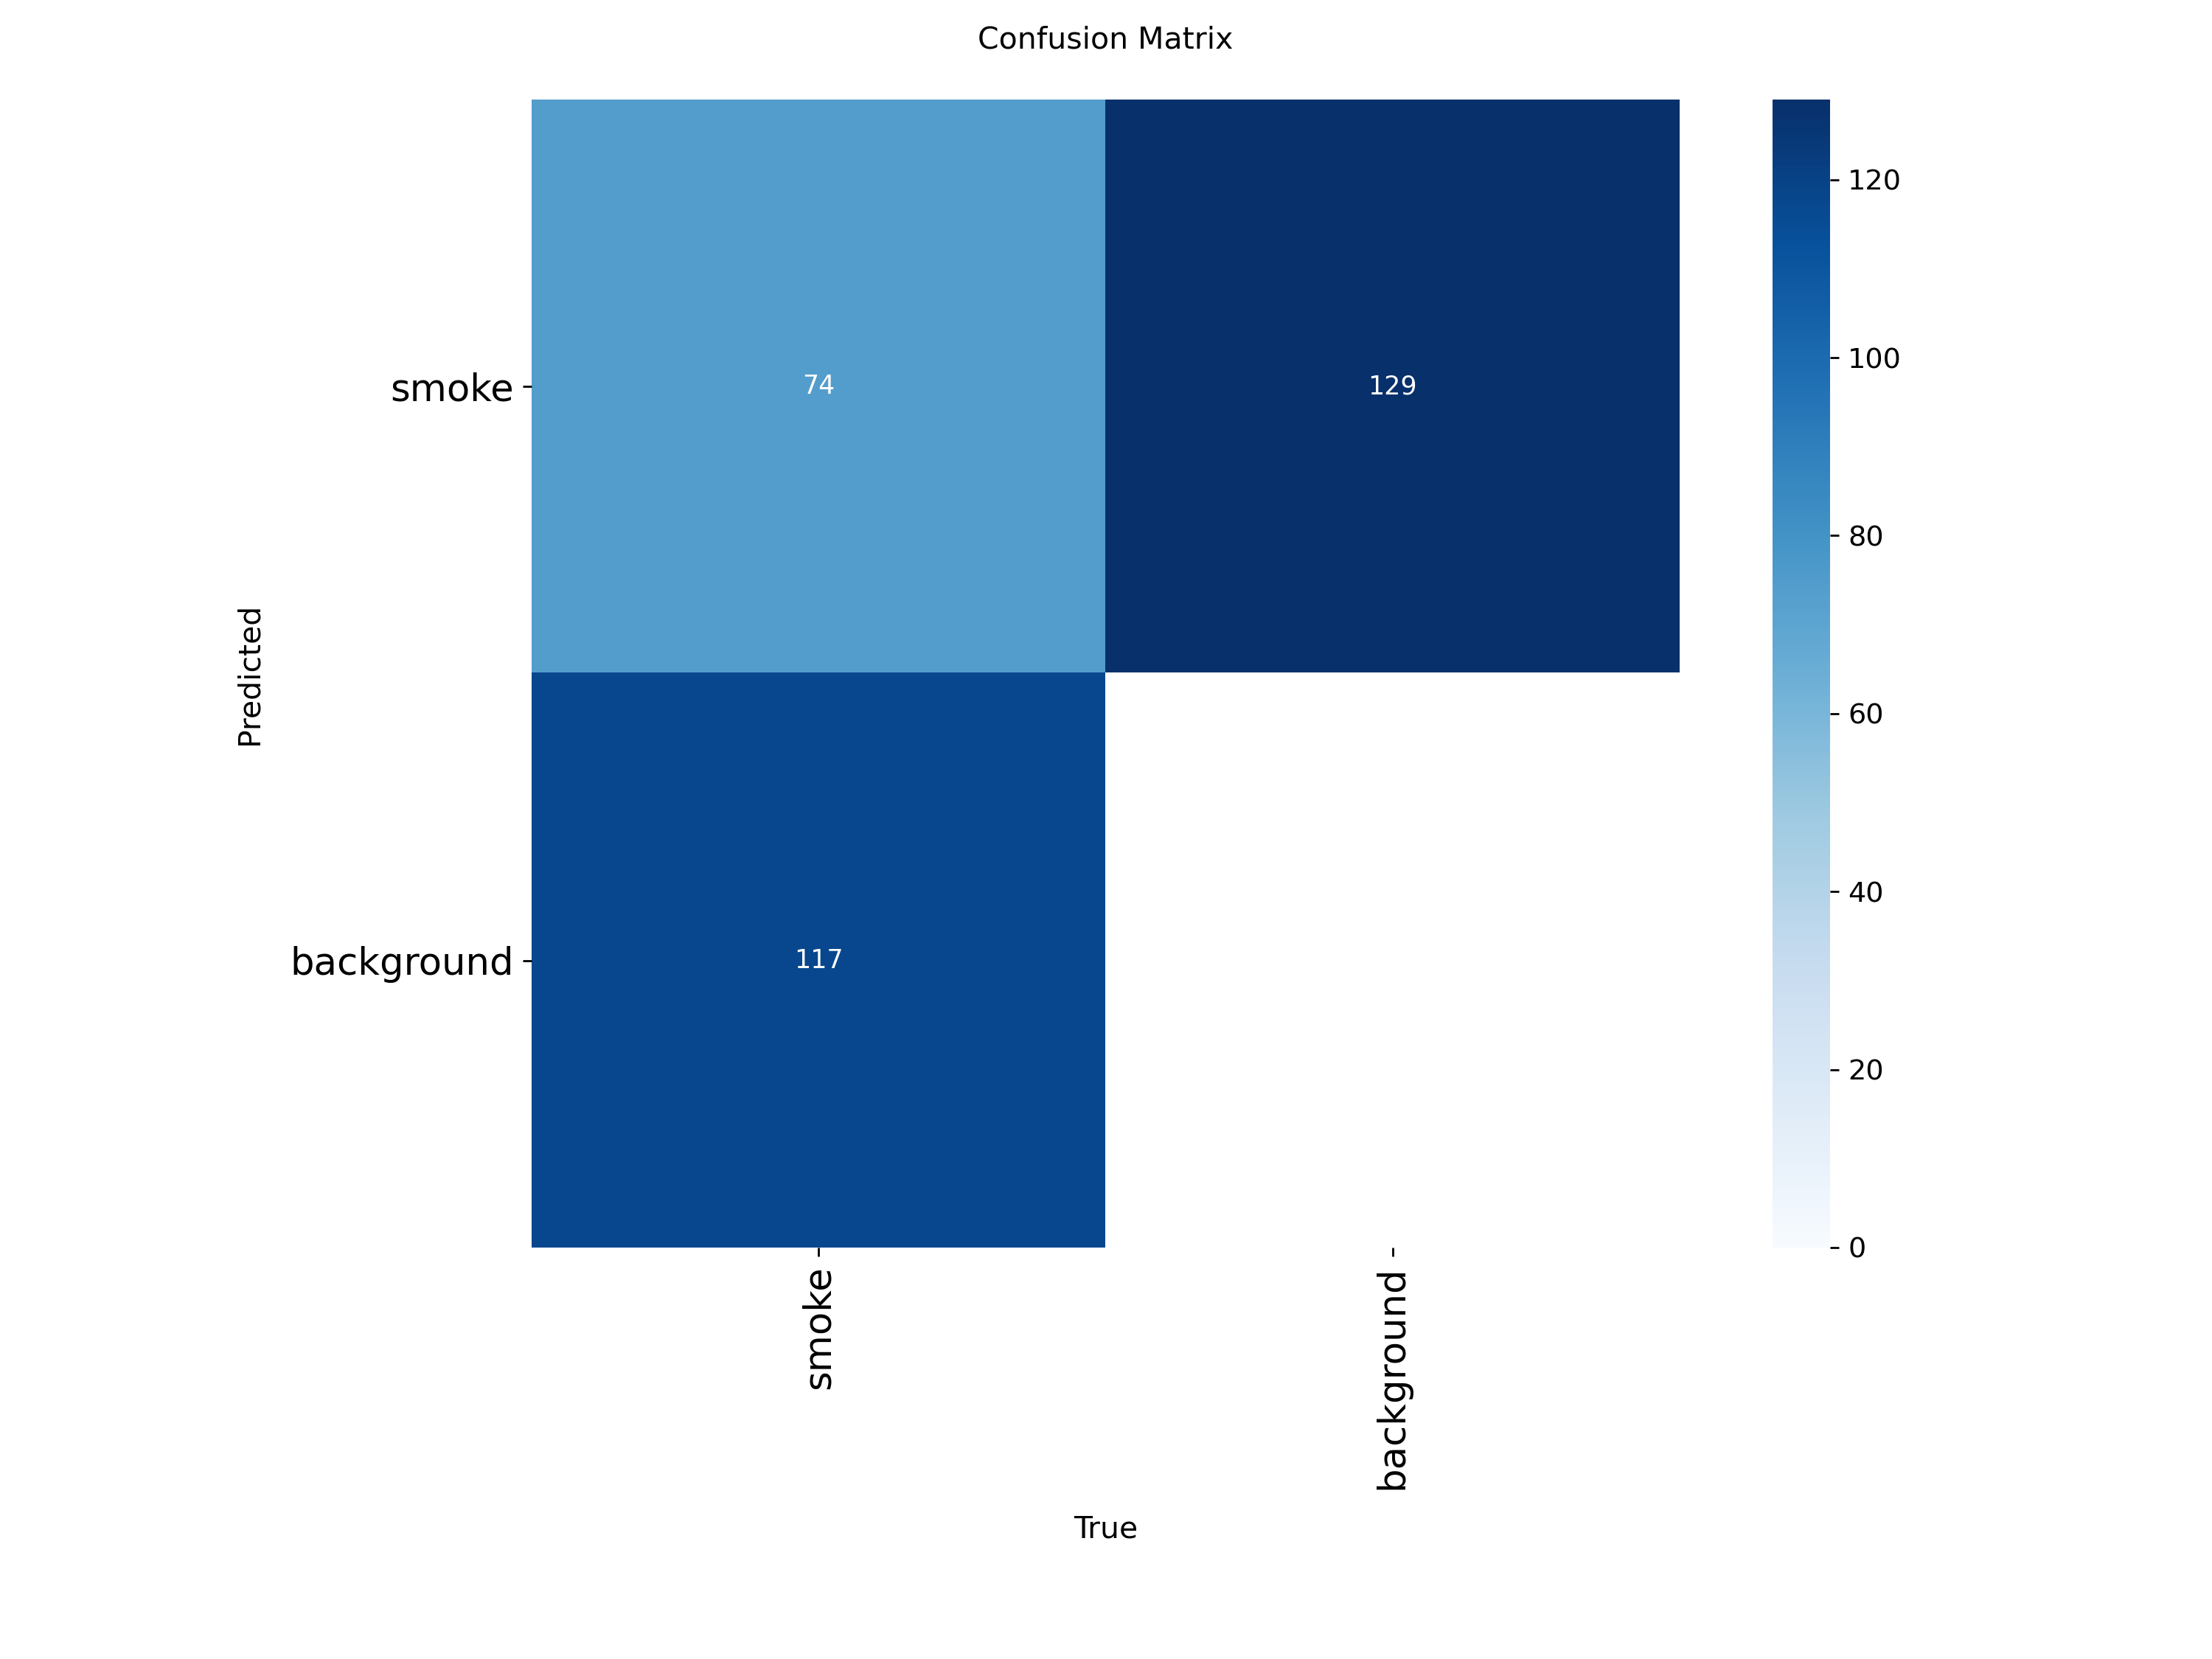

In [19]:
# Evaluate the same baseline using a 0.25 confidence threshold
baseline_conf025_metrics = baseline_model.val(
    data=str(dataset_dir / "data.yaml"),
    split="val",
    conf=0.25,
    plots=True,
    project=str(EVALUATION_DIR),
    name="baseline_conf025",
    exist_ok=True
)

# Display the confusion matrix for this threshold
display(Image(
    filename=str(EVALUATION_DIR / "baseline_conf025" / "confusion_matrix.png"),
    width=700
))

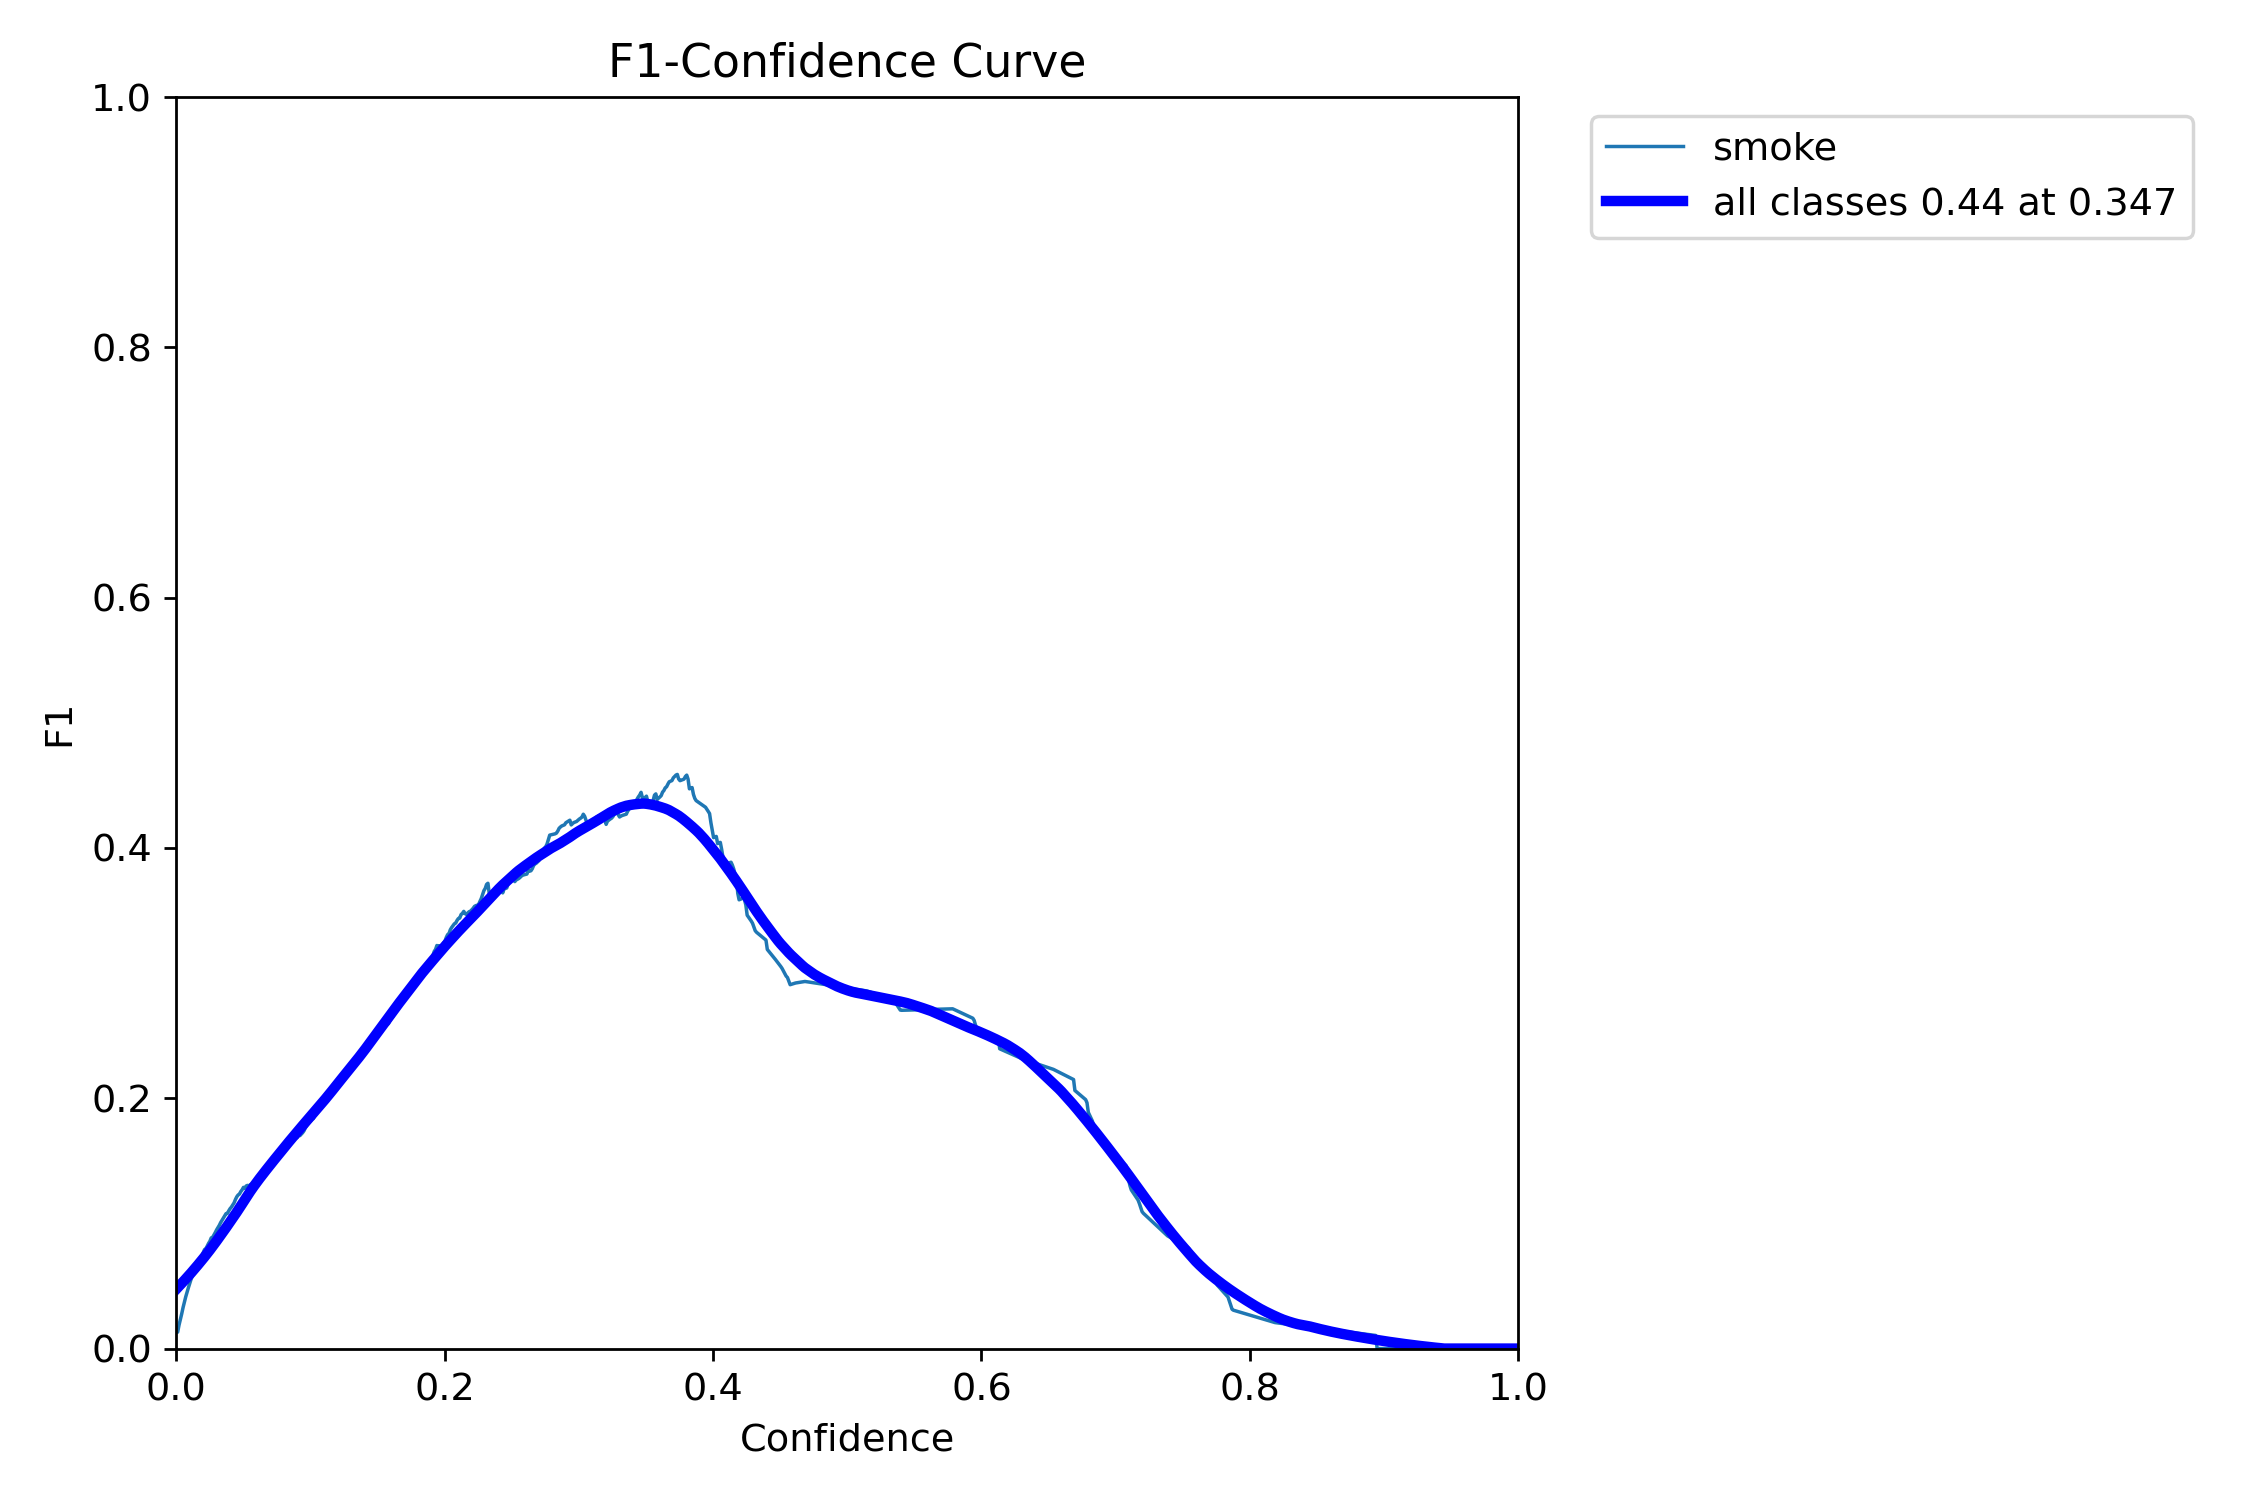

In [20]:
from IPython.display import Image, display

# Display the baseline's F1 score at different confidence thresholds
display(Image(
    filename=str(EVALUATION_DIR / "baseline" / "BoxF1_curve.png"),
    width=800
))

# Experiment 1
Higher image resolution

In [22]:
from ultralytics import YOLO

# EXPERIMENT 1: Higher image resolution
#
# Hypothesis:
# Training at 960 instead of 640 may improve detection of
# small or faint smoke plumes by preserving more image detail.
#
# Keep all other training parameters identical to the baseline.

experiment1_model = YOLO("yolo11n.pt")

experiment1_results = experiment1_model.train(
    data=str(dataset_dir / "data.yaml"),
    epochs=50,
    imgsz=960,             # Only intended change from baseline (640)
    batch=16,
    device=0,
    seed=42,
    deterministic=True,
    project="/content/drive/MyDrive/Wildfire_Smoke_Project/experiments",
    name="experiment_1_resolution960",
    exist_ok=True
)

Ultralytics 8.4.215 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=content/drive/MyDrive/smoke_dataset/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=960, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=experiment_1_resolution960, nbs=64, nms=Non

In [24]:
from ultralytics import YOLO

# Load the best checkpoint from Experiment 1
experiment1_best = YOLO(
    "/content/drive/MyDrive/Wildfire_Smoke_Project/"
    "experiments/experiment_1_resolution960/weights/best.pt"
)

# Evaluate using the same validation images as the baseline
experiment1_metrics = experiment1_best.val(
    data=str(dataset_dir / "data.yaml"),
    split="val",
    imgsz=960,
    plots=True,
    project=str(EVALUATION_DIR),
    name="experiment_1_resolution960",
    exist_ok=True
)

# Calculate precision, recall, and F1
precision = experiment1_metrics.box.mp
recall = experiment1_metrics.box.mr

f1 = (
    2 * precision * recall / (precision + recall)
    if precision + recall > 0
    else 0.0
)

# Display Experiment 1 metrics
print(f"Precision: {precision:.4f}")
print(f"Recall: {recall:.4f}")
print(f"F1: {f1:.4f}")
print(f"mAP@0.5: {experiment1_metrics.box.map50:.4f}")
print(f"mAP@0.5:0.95: {experiment1_metrics.box.map:.4f}")

Ultralytics 8.4.215 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11n summary (fused): 101 layers, 2,597,051 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 3434.9±811.4 MB/s, size: 337.4 KB)
val: Scanning /content/content/drive/MyDrive/smoke_dataset/labels/val.cache... 191 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 191/191 53.4Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 12/12 1.3it/s 8.9s
                   all        191        191      0.566      0.389      0.392      0.183
Speed: 4.5ms preprocess, 6.7ms inference, 0.0ms loss, 2.8ms postprocess per image
Results saved to /content/drive/MyDrive/Wildfire_Smoke_Project/evaluations/experiment_1_resolution960
Precision: 0.5661
Recall: 0.3894
F1: 0.4615
mAP@0.5: 0.3923
mAP@0.5:0.95: 0.1826


# Experiment 2
Add smoke-free images

In [11]:
from pathlib import Path

# Existing project directories
negative_images_dir = PROJECT_DIR / "negative_images"
negative_labels_dir = PROJECT_DIR / "negative_labels"

negative_labels_dir.mkdir(parents=True, exist_ok=True)

# Supported image extensions
image_extensions = {".jpg", ".jpeg", ".png"}

created = 0

# Generate empty annotation files for negative images
for image_path in negative_images_dir.rglob("*"):

    if not image_path.is_file():
        continue

    if image_path.suffix.lower() not in image_extensions:
        continue

    # Preserve subfolder structure if images are grouped by recording
    relative_path = image_path.relative_to(negative_images_dir)
    label_path = (
        negative_labels_dir / relative_path
    ).with_suffix(".txt")

    label_path.parent.mkdir(parents=True, exist_ok=True)

    # Avoid overwriting existing annotations
    if not label_path.exists():
        label_path.touch()
        created += 1

print(f"Created {created} empty annotation files.")

Created 969 empty annotation files.


In [5]:
# @title
from collections import Counter

# Display the first 20 filenames to inspect their naming pattern
print("Sample filenames:")
for image in image_files[:20]:
    print(image.name)

# Check for duplicate filenames
filename_counts = Counter(image.name for image in image_files)

duplicates = [
    name for name, count in filename_counts.items()
    if count > 1
]

print(f"\nTotal images: {len(image_files)}")
print(f"Duplicate filenames: {len(duplicates)}")

Sample filenames:
1465063200_-02400.jpg
1465063260_-02340.jpg
1465063268_-02400.jpg
1465063320_-02280.jpg
1465063328_-02340.jpg
1465063380_-02220.jpg
1465063388_-02280.jpg
1465063440_-02160.jpg
1465063448_-02220.jpg
1465063500_-02100.jpg
1465063508_-02160.jpg
1465063560_-02040.jpg
1465063568_-02100.jpg
1465063620_-01980.jpg
1465063628_-02040.jpg
1465063680_-01920.jpg
1465063688_-01980.jpg
1465063740_-01860.jpg
1465063748_-01920.jpg
1465063800_-01800.jpg

Total images: 969
Duplicate filenames: 0


In [12]:
# @title
from collections import defaultdict

# Determine the recording's reference timestamp from each filename
def get_recording_id(image_path):
    timestamp_str, offset_str = image_path.stem.rsplit("_", 1)

    timestamp = int(timestamp_str)
    offset = int(offset_str)

    # Frames from the same recording share a reference timestamp
    return timestamp - offset


# Group images by their recording ID
negative_groups = defaultdict(list)

for image in image_files:
    recording_id = get_recording_id(image)
    negative_groups[recording_id].append(image)

# Display the number of recordings and their image counts
print(f"Total smoke-free images: {len(image_files)}")
print(f"Unique recordings: {len(negative_groups)}")

print("\nImages per recording:")
for recording_id, images in sorted(negative_groups.items()):
    print(f"Recording {recording_id}: {len(images)} images")

Total smoke-free images: 969
Unique recordings: 26

Images per recording:
Recording 1465065600: 40 images
Recording 1465065668: 40 images
Recording 1466359357: 40 images
Recording 1466359453: 20 images
Recording 1466359567: 40 images
Recording 1468266071: 40 images
Recording 1468872421: 40 images
Recording 1468872498: 20 images
Recording 1468872972: 20 images
Recording 1469223121: 35 images
Recording 1469226498: 20 images
Recording 1479064369: 40 images
Recording 1479066933: 40 images
Recording 1495296879: 14 images
Recording 1495301827: 40 images
Recording 1497049647: 40 images
Recording 1497385096: 40 images
Recording 1498416078: 40 images
Recording 1498579057: 40 images
Recording 1498581432: 40 images
Recording 1499546263: 80 images
Recording 1499787397: 40 images
Recording 1499806131: 40 images
Recording 1499806193: 40 images
Recording 1499806467: 40 images
Recording 1499806611: 40 images


In [ ]:
from pathlib import Path
import re

# Extract the recording ID from a FIgLib filename
def get_recording_id(filename):
    match = re.match(r"^(\d+)_([+-]\d+)\.(jpg|jpeg|png)$", filename, re.I)

    if not match:
        return None

    timestamp = int(match.group(1))
    offset = int(match.group(2))

    return timestamp - offset


# Original training and validation images
training_images = PROJECT_DIR / "smoke_training" / "images" / "train"
validation_images = PROJECT_DIR / "smoke_training" / "images" / "val"

# Newly collected negative images
negative_images = PROJECT_DIR / "negative_images"


def collect_recordings(folder):
    recordings = set()

    for image in folder.rglob("*"):
        if image.is_file() and image.suffix.lower() in {".jpg", ".jpeg", ".png"}:
            recording_id = get_recording_id(image.name)

            if recording_id is not None:
                recordings.add(recording_id)

    return recordings


train_recordings = collect_recordings(training_images)
val_recordings = collect_recordings(validation_images)
negative_recordings = collect_recordings(negative_images)

print("Original training recordings:", len(train_recordings))
print("Original validation recordings:", len(val_recordings))
print("Negative image recordings:", len(negative_recordings))

print("\nNegative overlap with training:")
print(negative_recordings & train_recordings)

print("\nNegative overlap with validation:")
print(negative_recordings & val_recordings)


images/
  train
  val

labels/
  train
  train.cache
  val
  val.cache
Original training recordings: 0
Original validation recordings: 0
Negative image recordings: 26

Negative overlap with training:
set()

Negative overlap with validation:
set()


In [22]:
nonempty_labels = [
    path.name
    for path in negative_labels_dir.glob("*.txt")
    if path.read_text().strip()
]

print("Non-empty negative labels:", len(nonempty_labels))

Non-empty negative labels: 0


In [30]:
# @title
import shutil
from pathlib import Path

# EXPERIMENT 2: Create a dataset with smoke-free training images
#
# Copy the original dataset so our baseline remains unchanged.
# Then add the 180 negative images to the training split.

experiment2_dataset = Path(
    "/content/drive/MyDrive/Wildfire_Smoke_Project/datasets/experiment_2"
)

# Original dataset containing our baseline train/validation split
original_dataset = dataset_dir

# Create a separate copy of the original dataset
if not experiment2_dataset.exists():
    shutil.copytree(original_dataset, experiment2_dataset)

# Add smoke-free images and their empty YOLO labels
for image in negative_train_images:

    # Copy the image into Experiment 2's training directory
    shutil.copy2(
        image,
        experiment2_dataset / "images" / "train" / image.name
    )

    # Copy its corresponding empty annotation file
    shutil.copy2(
        negative_labels_dir / f"{image.stem}.txt",
        experiment2_dataset / "labels" / "train" / f"{image.stem}.txt"
    )

# Verify dataset sizes
train_count = len(list((experiment2_dataset / "images" / "train").glob("*.jpg")))
val_count = len(list((experiment2_dataset / "images" / "val").glob("*.jpg")))

print(f"Experiment 2 training images: {train_count}")
print(f"Experiment 2 validation images: {val_count}")

Experiment 2 training images: 813
Experiment 2 validation images: 191


In [31]:
# @title
import yaml

# EXPERIMENT 2: Configure the new dataset
#
# The dataset contains one detection class: smoke.
# Training includes 180 additional smoke-free images.
# Validation remains identical to the baseline.

experiment2_yaml = experiment2_dataset / "data.yaml"

dataset_config = {
    "path": str(experiment2_dataset),
    "train": "images/train",
    "val": "images/val",
    "nc": 1,
    "names": {0: "smoke"}
}

# Save the dataset configuration
with open(experiment2_yaml, "w") as file:
    yaml.safe_dump(dataset_config, file, sort_keys=False)

# Display the configuration for verification
print(experiment2_yaml.read_text())

path: /content/drive/MyDrive/Wildfire_Smoke_Project/datasets/experiment_2
train: images/train
val: images/val
nc: 1
names:
  0: smoke



In [32]:
from ultralytics import YOLO

# EXPERIMENT 2: Add smoke-free training images
#
# Hypothesis:
# Adding negative examples will help YOLO distinguish smoke
# from visually similar backgrounds, reducing false positives.
#
# All training settings match the original baseline.
# Only the training dataset has changed.

experiment2_model = YOLO("yolo11n.pt")

experiment2_results = experiment2_model.train(
    data=str(experiment2_yaml),
    epochs=50,
    imgsz=640,
    batch=16,
    device=0,
    seed=42,
    deterministic=True,
    project="/content/drive/MyDrive/Wildfire_Smoke_Project/experiments",
    name="experiment_2_negative_images",
    exist_ok=True
)

Ultralytics 8.4.215 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/drive/MyDrive/Wildfire_Smoke_Project/datasets/experiment_2/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=experiment_

In [33]:
from ultralytics import YOLO

# EXPERIMENT 2: Evaluate the model trained with smoke-free images
#
# Load the best checkpoint without retraining.
# Evaluate against the original 191 smoke-positive validation images
# so results are directly comparable with the baseline.

experiment2_best = YOLO(
    "/content/drive/MyDrive/Wildfire_Smoke_Project/"
    "experiments/experiment_2_negative_images/weights/best.pt"
)

experiment2_metrics = experiment2_best.val(
    data=str(experiment2_yaml),
    split="val",
    imgsz=640,
    plots=True,
    project=str(EVALUATION_DIR),
    name="experiment_2_negative_images",
    exist_ok=True
)

# Calculate F1 from reported mean precision and recall
precision = experiment2_metrics.box.mp
recall = experiment2_metrics.box.mr

f1 = (
    2 * precision * recall / (precision + recall)
    if precision + recall > 0
    else 0.0
)

# Display evaluation results
print(f"Precision: {precision:.4f}")
print(f"Recall: {recall:.4f}")
print(f"F1: {f1:.4f}")
print(f"mAP@0.5: {experiment2_metrics.box.map50:.4f}")
print(f"mAP@0.5:0.95: {experiment2_metrics.box.map:.4f}")

Ultralytics 8.4.215 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11n summary (fused): 101 layers, 2,597,051 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access ✅ (ping: 4.7±9.4 ms, read: 162.0±105.9 MB/s, size: 400.1 KB)
val: Scanning /content/drive/MyDrive/Wildfire_Smoke_Project/datasets/experiment_2/labels/val.cache... 191 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 191/191 33.4Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 12/12 1.5it/s 7.9s
                   all        191        191       0.62      0.351      0.331      0.147
Speed: 1.9ms preprocess, 3.9ms inference, 0.0ms loss, 2.6ms postprocess per image
Results saved to /content/drive/MyDrive/Wildfire_Smoke_Project/evaluations/experiment_2_negative_images
Precision: 0.6197
Recall: 0.3508
F1: 0.4480
mAP@0.5: 0.3313
mAP@0.5:0.95: 0.1466


In [34]:
# Compare false alarms on the 40 reserved smoke-free images.
#
# All three models use the same images and confidence threshold.
# Since these images contain no smoke, every predicted smoke box
# is a false positive.

models_to_test = {
    "Baseline": baseline_model,
    "Experiment 1": experiment1_best,
    "Experiment 2": experiment2_best
}

confidence_threshold = 0.25

for model_name, model in models_to_test.items():

    false_positives = 0
    images_with_false_alarms = 0

    # Evaluate each smoke-free image individually
    for image in negative_eval_images:

        results = model.predict(
            source=str(image),
            conf=confidence_threshold,
            verbose=False
        )

        # Count predicted smoke boxes
        detections = len(results[0].boxes)

        false_positives += detections

        if detections > 0:
            images_with_false_alarms += 1

    print(f"\n{model_name}")
    print(f"Total false-positive boxes: {false_positives}")
    print(f"Images with false alarms: {images_with_false_alarms}/40")


Baseline
Total false-positive boxes: 0
Images with false alarms: 0/40

Experiment 1
Total false-positive boxes: 0
Images with false alarms: 0/40

Experiment 2
Total false-positive boxes: 0
Images with false alarms: 0/40


# False Negatives & Positives

In [36]:
# ERROR ANALYSIS: Save predictions from our best-performing model
#
# Use Experiment 1 (960 resolution) to generate bounding boxes
# on the original validation images.
# These images will help us inspect detection mistakes.

error_analysis_results = experiment1_best.predict(
    source=str(dataset_dir / "images" / "val"),
    imgsz=960,
    conf=0.25,
    save=True,
    project="/content/drive/MyDrive/Wildfire_Smoke_Project/evaluations",
    name="experiment_1_predictions",
    exist_ok=True,
    verbose=False
)

print(f"Saved predictions for {len(error_analysis_results)} images")

Results saved to /content/drive/MyDrive/Wildfire_Smoke_Project/evaluations/experiment_1_predictions
Saved predictions for 191 images


In [37]:
from collections import defaultdict
from ultralytics.utils.metrics import box_iou
import torch

# ERROR ANALYSIS: Compare predicted boxes against ground-truth boxes.
#
# This uses the predictions already generated in the previous cell.
# We match predictions to annotations using an IoU threshold of 0.5.
# Each annotation can be matched to at most one prediction.

error_summary = []

for image, result in zip(
    sorted((dataset_dir / "images" / "val").glob("*.jpg")),
    error_analysis_results
):
    # Read the ground-truth YOLO annotations
    label_path = dataset_dir / "labels" / "val" / f"{image.stem}.txt"

    ground_truth = []

    if label_path.exists():
        for line in label_path.read_text().splitlines():
            values = list(map(float, line.split()))
            if len(values) == 5:
                _, x, y, w, h = values

                # Convert normalized YOLO coordinates to pixel coordinates
                img_h, img_w = result.orig_shape

                ground_truth.append([
                    (x - w / 2) * img_w,
                    (y - h / 2) * img_h,
                    (x + w / 2) * img_w,
                    (y + h / 2) * img_h
                ])

    # Predicted bounding boxes
    predicted_boxes = result.boxes.xyxy.cpu()

    gt_boxes = (
        torch.tensor(ground_truth, dtype=torch.float32)
        if ground_truth
        else torch.empty((0, 4))
    )

    # Match predictions to ground truth using IoU
    matched_predictions = set()
    matched_ground_truth = set()

    if len(predicted_boxes) and len(gt_boxes):
        ious = box_iou(predicted_boxes, gt_boxes)

        # Match highest-IoU pairs first to avoid duplicate matches
        candidates = [
            (ious[i, j].item(), i, j)
            for i in range(len(predicted_boxes))
            for j in range(len(gt_boxes))
            if ious[i, j] >= 0.5
        ]

        for iou, i, j in sorted(candidates, reverse=True):
            if i not in matched_predictions and j not in matched_ground_truth:
                matched_predictions.add(i)
                matched_ground_truth.add(j)

    false_positives = len(predicted_boxes) - len(matched_predictions)
    false_negatives = len(gt_boxes) - len(matched_ground_truth)

    error_summary.append({
        "image": image.name,
        "false_positives": false_positives,
        "false_negatives": false_negatives
    })

# Show images with the most false positives and false negatives
print("Top false-positive images:")
for item in sorted(
    error_summary,
    key=lambda x: x["false_positives"],
    reverse=True
)[:10]:
    print(item)

print("\nTop false-negative images:")
for item in sorted(
    error_summary,
    key=lambda x: x["false_negatives"],
    reverse=True
)[:10]:
    print(item)

Top false-positive images:
{'image': '1717877411_+00240.jpg', 'false_positives': 1, 'false_negatives': 1}
{'image': '1717877651_+00480.jpg', 'false_positives': 1, 'false_negatives': 1}
{'image': '1717877711_+00540.jpg', 'false_positives': 1, 'false_negatives': 1}
{'image': '1719856071_+01021.jpg', 'false_positives': 1, 'false_negatives': 1}
{'image': '1719856130_+01080.jpg', 'false_positives': 1, 'false_negatives': 1}
{'image': '1719856311_+01261.jpg', 'false_positives': 1, 'false_negatives': 1}
{'image': '1719856371_+01321.jpg', 'false_positives': 1, 'false_negatives': 0}
{'image': '1719856431_+01381.jpg', 'false_positives': 1, 'false_negatives': 1}
{'image': '1721429452_+00839.jpg', 'false_positives': 1, 'false_negatives': 1}
{'image': '1722195601_-00840.jpg', 'false_positives': 1, 'false_negatives': 1}

Top false-negative images:
{'image': '1612466053_+00300.jpg', 'false_positives': 0, 'false_negatives': 1}
{'image': '1612466113_+00360.jpg', 'false_positives': 0, 'false_negatives': 

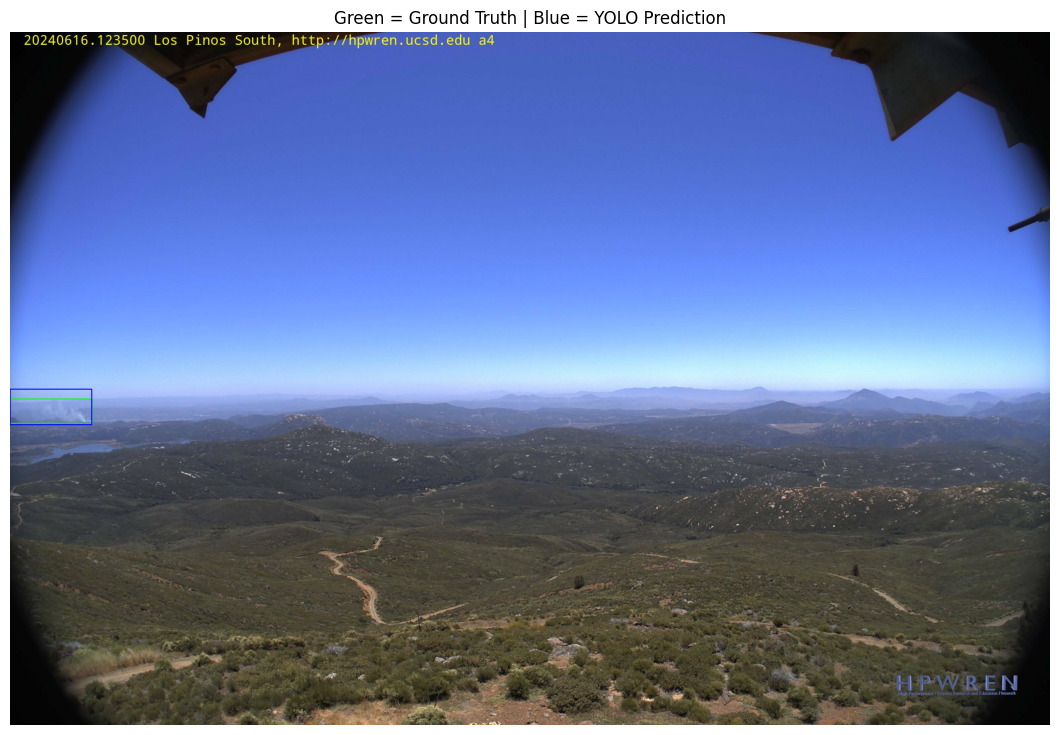

Ground-truth label exists: True
Predicted boxes: 1
IoU between predicted and annotated boxes:
tensor([[0.6879]])


In [64]:
# @title
import cv2
import matplotlib.pyplot as plt
from pathlib import Path

# Image we want to investigate
image_name = "1718566500_+01320.jpg"

# Locate the original image and its annotation
image_path = dataset_dir / "images" / "val" / image_name
label_path = dataset_dir / "labels" / "val" / f"{Path(image_name).stem}.txt"

# Load the original image
image = cv2.imread(str(image_path))
assert image is not None, f"Image not found: {image_path}"

height, width = image.shape[:2]

# Draw ground-truth boxes in green
if label_path.exists():
    for line in label_path.read_text().splitlines():
        class_id, x, y, w, h = map(float, line.split())

        # Convert normalized YOLO coordinates into pixel coordinates
        x1 = int((x - w / 2) * width)
        y1 = int((y - h / 2) * height)
        x2 = int((x + w / 2) * width)
        y2 = int((y + h / 2) * height)

        cv2.rectangle(image, (x1, y1), (x2, y2), (0, 255, 0), 2)

# Generate predictions using Experiment 1
results = experiment1_best.predict(
    source=str(image_path),
    imgsz=960,
    conf=0.25,
    verbose=False
)

# Draw predicted boxes in blue
for box in results[0].boxes:
    x1, y1, x2, y2 = map(int, box.xyxy[0].tolist())

    cv2.rectangle(image, (x1, y1), (x2, y2), (255, 0, 0), 2)

# Convert BGR to RGB for Matplotlib
image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

# Display both types of bounding boxes
plt.figure(figsize=(14, 9))
plt.imshow(image)
plt.title("Green = Ground Truth | Blue = YOLO Prediction")
plt.axis("off")
plt.show()

print(f"Ground-truth label exists: {label_path.exists()}")
print(f"Predicted boxes: {len(results[0].boxes)}")

from ultralytics.utils.metrics import box_iou
import torch

# Compare the predicted boxes with the original annotation
pred_boxes = results[0].boxes.xyxy.cpu()

# ground_truth_boxes should contain the original annotation
# coordinates in pixel-space xyxy format.
ground_truth_boxes = torch.tensor(
    [
        [
            (x - w / 2) * width,
            (y - h / 2) * height,
            (x + w / 2) * width,
            (y + h / 2) * height
        ]
        for _, x, y, w, h in (
            map(float, line.split())
            for line in label_path.read_text().splitlines()
        )
    ],
    dtype=torch.float32
)

ious = box_iou(pred_boxes, ground_truth_boxes)

print("IoU between predicted and annotated boxes:")
print(ious)

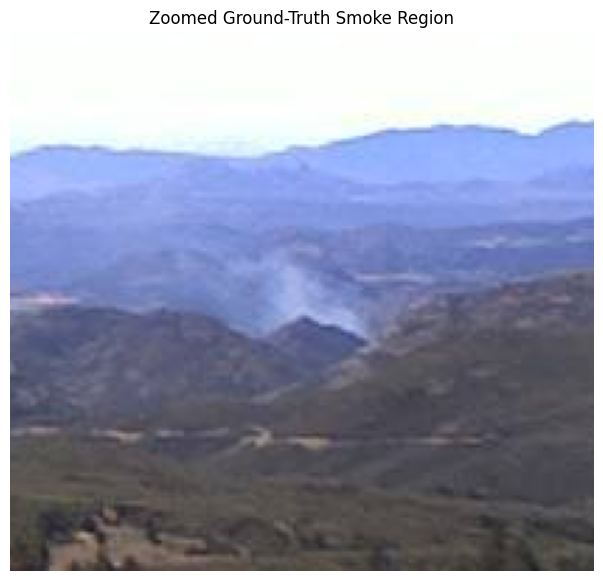

In [57]:
# @title
# ERROR ANALYSIS: Zoom in on the ground-truth smoke annotation
#
# This helps us inspect very small plumes without resizing
# the entire image.

original = cv2.imread(str(image_path))
original = cv2.cvtColor(original, cv2.COLOR_BGR2RGB)

# Read the first ground-truth bounding box
_, x, y, w, h = map(
    float,
    label_path.read_text().splitlines()[0].split()
)

img_h, img_w = original.shape[:2]

# Convert normalized coordinates to pixel coordinates
x1 = int((x - w / 2) * img_w)
y1 = int((y - h / 2) * img_h)
x2 = int((x + w / 2) * img_w)
y2 = int((y + h / 2) * img_h)

# Include surrounding scenery for context
padding = 80

crop = original[
    max(0, y1 - padding):min(img_h, y2 + padding),
    max(0, x1 - padding):min(img_w, x2 + padding)
]

plt.figure(figsize=(10, 7))
plt.imshow(crop)
plt.title("Zoomed Ground-Truth Smoke Region")
plt.axis("off")
plt.show()

In [58]:
# @title
# Find validation images with at least one correct smoke detection
# and no false positives or false negatives.

successful_images = []

for item in error_summary:
    if item["false_positives"] == 0 and item["false_negatives"] == 0:
        image_name = item["image"]

        # Confirm that YOLO actually detected smoke
        result = next(
            (r for r in error_analysis_results
             if Path(r.path).name == image_name),
            None
        )

        if result is not None and len(result.boxes) > 0:
            successful_images.append(image_name)

print(f"Successful detection images: {len(successful_images)}")

print("\nFirst 10 successful images:")
for name in successful_images[:10]:
    print(name)

Successful detection images: 50

First 10 successful images:
1717877471_+00300.jpg
1717877531_+00360.jpg
1718565601_+00421.jpg
1718566500_+01320.jpg
1718566561_+01381.jpg
1719855351_+00301.jpg
1719855771_+00721.jpg
1719855831_+00781.jpg
1719856010_+00960.jpg
1719856192_+01142.jpg


# Try a bigger model (YOLO11s)

In [ ]:
from ultralytics import YOLO

# EXPERIMENT 3: Larger YOLO model
#
# Hypothesis:
# YOLO11s may learn more detailed visual features than YOLO11n,
# improving detection of faint smoke and localization accuracy.

experiment3_model = YOLO("yolo11s.pt")

experiment3_results = experiment3_model.train(
    data=str(dataset_dir / "data.yaml"),
    epochs=50,
    imgsz=960,
    batch=-1,  # Automatically select a batch size for available GPU memory
    device=0,
    seed=42,
    deterministic=True,
    project="/content/drive/MyDrive/Wildfire_Smoke_Project/experiments",
    name="experiment_3_yolo11s",
    exist_ok=True
)

Ultralytics 8.4.215 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=-1, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=content/drive/MyDrive/smoke_dataset/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=960, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11s.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=experiment_3_yolo11s, nbs=64, nms=None, ops